# 04 · Training comparison: sample complexity of five policy-gradient methods

Structure: **setup** (methods, protocol, reference policies) → **pilot run and target** → **step-size tuning** →
**final runs** (learning curves, sample complexity, poems before/after) → **discussion**.

All runs use the MDP and the final reward of notebook 03, with KL coefficient η = 0.5. The policy is a tabular softmax with
$\tau = 1$, initialised at the bigram ($\theta_0 = \tau\log P_{\text{bigram}}$).

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from poet import experiments as X, protocol as P, evaluate as ev, stats
from poet.estimators import LABELS
from poet.policy import TabularSoftmax

plt.rcParams['figure.dpi'] = 110
COLORS = {m: f'C{k}' for k, m in enumerate(P.METHODS)}
env = X.make_env({})
print('reward config:', env.cfg)
print(f'budget: {P.N_EPISODES:,} training episodes per run, evaluation every {P.EVAL_EVERY} episodes on 200 fresh poems')

reward config: RewardConfig(syllable_weight=1.0, exact_line_bonus=3.0, poem_bonus=10.0, fluency_weight=0.03, repeat_penalty=2.0, overflow_penalty=1.0, progress=True, kl_coef=0.5, sparse=False)
budget: 100,000 training episodes per run, evaluation every 1000 episodes on 200 fresh poems


## 1. The five methods

| method | gradient estimate |
|---|---|
| REINFORCE | $\frac1n\sum_i \big[\sum_t \nabla\log\pi(A^i_t\mid S^i_t)\big]\, R(\tau_i)$ |
| REINFORCE + baseline | same, with $R(\tau_i) - b_i$, $b_i$ = leave-one-out mean return of the batch |
| GPOMDP | $\frac1n\sum_i \sum_t \nabla\log\pi(A^i_t\mid S^i_t) \sum_{h\ge t} r^i_h$ |
| GPOMDP + $b_t$ | $\frac1n\sum_i\sum_t (r^i_t - b_t)\sum_{h\le t}\nabla\log\pi(A^i_h\mid S^i_h)$, $b_t$ = leave-one-out mean reward at step $t$ |
| Actor-critic | per step: $\delta_t = r_t + V_w(S_{t+1}) - V_w(S_t)$, $\theta \mathrel{+}= \alpha\,\delta_t\nabla\log\pi(A_t\mid S_t)$, $V_w(S_t) \mathrel{+}= \beta\,\delta_t$ |

Batch methods: batch size $n = 10$ episodes and plain gradient ascent $\theta \leftarrow \theta + \alpha\,\hat g$. Episodes have
variable length (at most $T=26$). The finite-horizon estimators treat them as length-$T$ episodes with zero reward after the end,
and $b_t$ averages over all $n$ padded episodes (notebook 02 shows why the sum must run to $T$).

**Actor-critic: adapting the simplified advantage actor-critic to our setting.** The standard algorithm is stated for the *discounted, infinite-horizon*
setting. Its actor step is $\theta \leftarrow \theta + \frac{\alpha}{1-\gamma}\,\delta_t\,\nabla\log\pi(A_t\mid S_t)$. The factor $\frac1{1-\gamma}$ comes from the
policy gradient theorem written with the *normalised* discounted state-occupancy measure $d^\pi_\gamma$. Our poems are
episodic and undiscounted, so we use:
- $\gamma = 1$ and $V_w(\text{terminal}) = 0$, so $\delta_t = r_t + V_w(S_{t+1}) - V_w(S_t)$ with $V_w(S_T) = 0$ at the end of the poem;
- **no** $\frac{1}{1-\gamma}$ factor. It is undefined at $\gamma=1$, and with a finite horizon the gradient is
  $\mathbb E\big[\sum_t \nabla\log\pi(A_t\mid S_t)\,A^\pi(S_t,A_t)\big]$ (the finite-horizon policy gradient theorem with the advantage), i.e. a *sum* over the steps of the
  episode, not an average under a normalised occupancy measure. Updating at every step implements exactly that sum, and
  $\delta_t$ is a (critic-biased) estimate of $A^\pi(S_t,A_t)$;
- a tabular critic $V_w$ on the same enriched state, trained by TD(0) (the critic update, where $\nabla_w V_w(S_t)$ is an indicator);
- actor step $\alpha \ll$ critic step $\beta$, as is standard for actor-critic methods: $\beta = \min(10\alpha, 1)$. The cap keeps the tabular TD update a convex
  combination of old value and target, so it cannot diverge.

**Fair comparison.** Every method gets the same budget ($10^5$ training episodes per run) and the **same step-size grid**, tuned with
the same number of runs (3 seeds per grid value). The x-axis is always *training episodes*. Evaluation uses 200 fresh poems,
sampled with a separate generator, that are not counted in the budget. On the same grid the actor-critic's effective step is larger,
because it makes about 20 updates per episode while a batch method makes one update per 10 episodes. That is why the grid is wide,
and why it is extended for all methods if any method's best value is at an edge.

In [2]:
# Reference points: the untrained bigram and the uniform random policy (2000 fresh poems each)
refs = {}
for name, logits in [('bigram (untrained)', env.bigram_logits(1.0)), ('uniform random', env.uniform_logits())]:
    pol = TabularSoftmax(logits, 1.0)
    refs[name] = ev.poem_metrics(env, ev.sample_poems(env, pol, 2000, np.random.default_rng(7)))
    m = refs[name]
    print(f"{name:20s} return {m['return']:6.2f} | valid {m['valid']:.1%} | distinct poems {m['distinct_poems']:.0%} | "
          f"syllable error/line {m['syl_error']:.2f} | overflow {m['overflow']:.0%}")

bigram (untrained)   return   4.41 | valid 0.0% | distinct poems 100% | syllable error/line 2.77 | overflow 66%


uniform random       return  -0.38 | valid 0.0% | distinct poems 100% | syllable error/line 3.24 | overflow 99%


## 2. Pilot run

One run of GPOMDP + $b_t$ with $\alpha = 1$ (the setting of notebook 03) on a seed not used anywhere else (1000), for the full budget.
Its only purpose is to see the scale of the learning curve before fixing the target.

all 1 runs loaded from 04_pilot.pkl


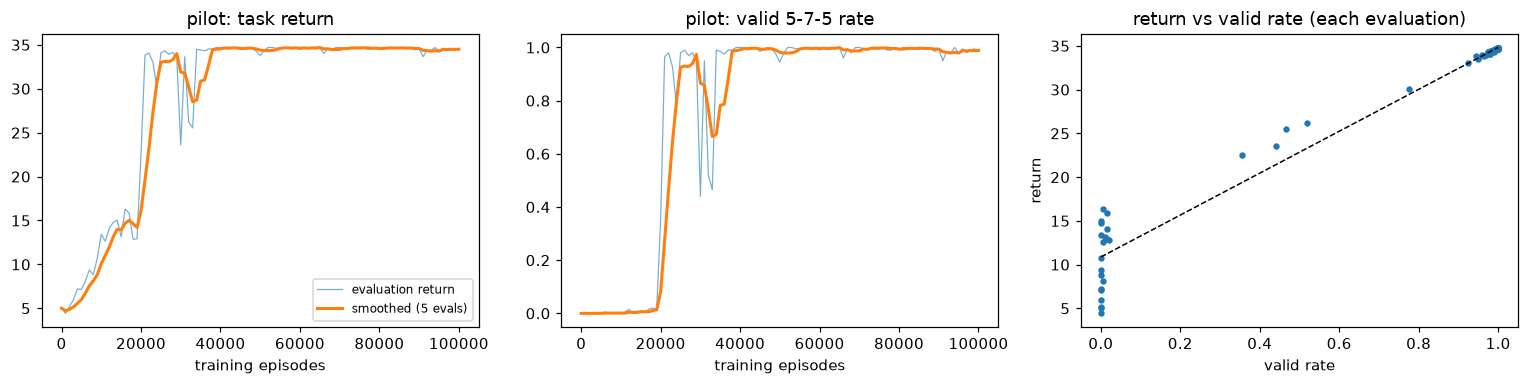

plateau (last 20 evaluations): return 34.51, valid 0.990; initial return 5.02
linear fit: return = 10.9 + 23.9 * valid   (correlation 0.98)


In [3]:
pilot = X.run_many([P.spec('gpomdp_b', 1.0, P.PILOT_SEED)], X.RESULTS_DIR / '04_pilot.pkl')[0]
h = pilot['history']
x = np.array(h['eval_episodes'])
R, v = np.array(h['eval_return']), np.array(h['eval_valid'])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(x, R, lw=0.8, alpha=0.6, label='evaluation return'); axes[0].plot(x, P.smoothed(h), lw=2, label=f'smoothed ({P.SMOOTH} evals)')
axes[1].plot(x, v, lw=0.8, alpha=0.6); axes[1].plot(x, P.smoothed(h, 'valid'), lw=2)
axes[2].scatter(v, R, s=10)
slope, intercept = np.polyfit(v, R, 1)
axes[2].plot([0, 1], [intercept, intercept + slope], 'k--', lw=1)
axes[0].set_title('pilot: task return'); axes[1].set_title('pilot: valid 5-7-5 rate'); axes[2].set_title('return vs valid rate (each evaluation)')
for ax in axes[:2]: ax.set_xlabel('training episodes')
axes[2].set_xlabel('valid rate'); axes[2].set_ylabel('return'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f'plateau (last 20 evaluations): return {R[-20:].mean():.2f}, valid {v[-20:].mean():.3f}; initial return {R[0]:.2f}')
print(f'linear fit: return = {intercept:.1f} + {slope:.1f} * valid   (correlation {np.corrcoef(v, R)[0, 1]:.2f})')

## 3. Target performance (fixed after the pilot, before tuning and final runs)

The targets were fixed after looking **only at the pilot above**, and written to `results/04_target.json` (with a timestamp) before any
tuning or final run had finished:

- **Return target $J^\star = 30$.** A valid haiku earns the full syllable progress (17), three exact-line bonuses (9) and the completion
  bonus (10), minus a small fluency cost, so about 34–35 (the pilot plateau is 34.5). A poem with one wrong line earns about 15–22. On the
  pilot, return and valid rate lie on a line, return ≈ 10.9 + 23.9 · valid, so $J^\star = 30$ means that **about 80% of the poems are exact
  5-7-5 haiku**. It sits clearly below the plateau, so a converged run is not kept under the target by evaluation noise.
- **Valid-rate target 0.8**, the same level expressed directly as the share of valid 5-7-5 poems.
- **Sample complexity** = the first training episode at which the evaluation curve, **smoothed over 5 evaluations (5000 episodes)**,
  reaches the target. Smoothing prevents a single lucky evaluation from counting. A run that never reaches the target within the
  budget is reported as *not reached*, never dropped.

On the pilot both targets are reached at 24 000 episodes.

In [4]:
# The decision above, as data. On a run from scratch (empty results/) this cell writes the file right after the pilot,
# before any tuning or final run, exactly as it was done originally; afterwards it only reads it.
TARGET_FILE = X.RESULTS_DIR / '04_target.json'
if not TARGET_FILE.exists():
    import datetime
    json.dump({'fixed_at': datetime.datetime.now(datetime.timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ'),
               'fixed_after': 'pilot run only (GPOMDP + b_t, alpha = 1, seed 1000, 100k episodes); before tuning results and final runs',
               'return_target': 30.0, 'valid_target': 0.8, 'smoothing_window_evals': P.SMOOTH}, open(TARGET_FILE, 'w'), indent=2)
target = json.load(open(TARGET_FILE))
TARGET_RETURN, TARGET_VALID = target['return_target'], target['valid_target']
assert target['smoothing_window_evals'] == P.SMOOTH
print(f"targets fixed at {target['fixed_at']}: return >= {TARGET_RETURN}, valid rate >= {TARGET_VALID}")
print('pilot sample complexity:', P.sample_complexity(h, TARGET_RETURN), '(return),',
      P.sample_complexity(h, TARGET_VALID, 'valid'), '(valid rate)')

targets fixed at 2026-10-13T15:39:39Z: return >= 30.0, valid rate >= 0.8
pilot sample complexity: 24000 (return), 24000 (valid rate)


## 4. Step-size tuning

Each method is run on the grid $\alpha \in \{0.01, 0.03, 0.1, 0.3, 1, 3\}$ with 3 seeds (0, 1, 2) and the full budget. The tuning
criterion is the **mean evaluation return over the whole budget** (the area under the learning curve divided by the budget). It rewards
learning *early*, and it does not use the target. If any method's best $\alpha$ is at an edge of the grid, the grid is extended by one
value on that side **for all methods**, and the loop repeats.

In [5]:
TUNE_CACHE = X.RESULTS_DIR / '04_tuning.pkl'
grid = list(P.ALPHA_GRID)
while True:
    specs = [P.spec(m, a, s) for m in P.METHODS for a in grid for s in P.TUNE_SEEDS]
    results = X.run_many(specs, TUNE_CACHE)
    scores = {}
    for sp, r in zip(specs, results):
        scores.setdefault((sp['method'], sp['alpha']), []).append(P.tuning_score(r))
    best = {m: max(grid, key=lambda a: np.mean(scores[(m, a)])) for m in P.METHODS}
    new_grid = P.extend_grid(grid, best)
    if new_grid == grid:
        break
    print(f'best alpha at a grid edge {best} -> extending the grid to {new_grid}')
    grid = new_grid

print(f'\nmean evaluation return over the budget (3 seeds); grid = {grid}')
print(f'{"method":24s}' + ''.join(f'{a:>9}' for a in grid))
for m in P.METHODS:
    print(f'{LABELS[m]:24s}' + ''.join(f'{np.mean(scores[(m, a)]):9.2f}' for a in grid) + f'   best alpha = {best[m]}')

all 90 runs loaded from 04_tuning.pkl
best alpha at a grid edge {'reinforce': 3.0, 'reinforce_b': 3.0, 'gpomdp': 3.0, 'gpomdp_b': 3.0, 'ac': 1.0} -> extending the grid to [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]


all 105 runs loaded from 04_tuning.pkl

mean evaluation return over the budget (3 seeds); grid = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
method                       0.01     0.03      0.1      0.3      1.0      3.0     10.0
REINFORCE                    4.48     4.77     7.03    14.82    30.03    33.33     9.62   best alpha = 3.0
REINFORCE + baseline         4.50     4.78     6.78    12.81    28.67    33.72    15.12   best alpha = 3.0
GPOMDP                       4.50     4.76     6.80    11.97    31.06    33.83    33.82   best alpha = 3.0
GPOMDP + baseline b_t        4.47     4.75     6.98    10.96    26.99    33.67    29.25   best alpha = 3.0
Actor-critic                 6.36    10.49    29.14    33.17    33.92    15.53    13.19   best alpha = 1.0


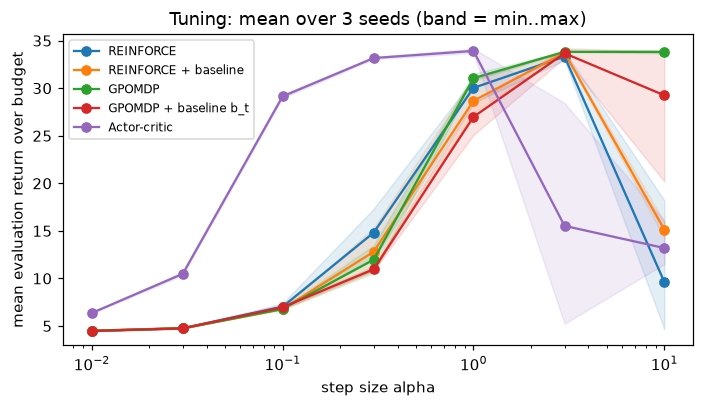

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for m in P.METHODS:
    mean = [np.mean(scores[(m, a)]) for a in grid]
    lo = [min(scores[(m, a)]) for a in grid]; hi = [max(scores[(m, a)]) for a in grid]
    ax.plot(grid, mean, 'o-', color=COLORS[m], label=LABELS[m])
    ax.fill_between(grid, lo, hi, color=COLORS[m], alpha=0.12)
ax.set_xscale('log'); ax.set_xlabel('step size alpha'); ax.set_ylabel('mean evaluation return over budget')
ax.set_title('Tuning: mean over 3 seeds (band = min..max)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Sample complexity across the whole grid

The tuning runs also give the sample complexity of every method at every step size, measured against the same target (fixed in §3).
This shows *how* each method depends on α, not only its best value. Left: median training episodes to the return target over the
3 tuning seeds, with "not reached" counted as the budget and marked ×. Right: share of distinct poems at the end of training.

episodes to return >= 30.0 (thousands) per tuning seed, "-" = not reached; final share of distinct poems
method                                0.01              0.03               0.1               0.3               1.0               3.0              10.0


REINFORCE                    -/-/-  d=1.00     -/-/-  d=1.00     -/-/-  d=1.00   -/74/86  d=0.06  28/17/19  d=0.01     8/5/8  d=0.01    -/75/-  d=0.01


REINFORCE + baseline         -/-/-  d=1.00     -/-/-  d=1.00     -/-/-  d=1.00    -/84/-  d=0.63  32/33/15  d=0.68     7/6/6  d=0.01     -/-/-  d=0.01


GPOMDP                       -/-/-  d=1.00     -/-/-  d=1.00     -/-/-  d=1.00    -/-/93  d=0.43  18/19/15  d=0.01     6/5/6  d=0.01     5/5/5  d=0.01


GPOMDP + baseline b_t        -/-/-  d=1.00     -/-/-  d=1.00     -/-/-  d=1.00     -/-/-  d=0.90  32/30/46  d=0.52     8/5/7  d=0.05     5/-/5  d=0.01


Actor-critic                 -/-/-  d=1.00     -/-/-  d=1.00  28/27/26  d=0.02     9/9/8  d=0.01     6/5/6  d=0.01    -/28/5  d=0.01     -/-/-  d=0.01


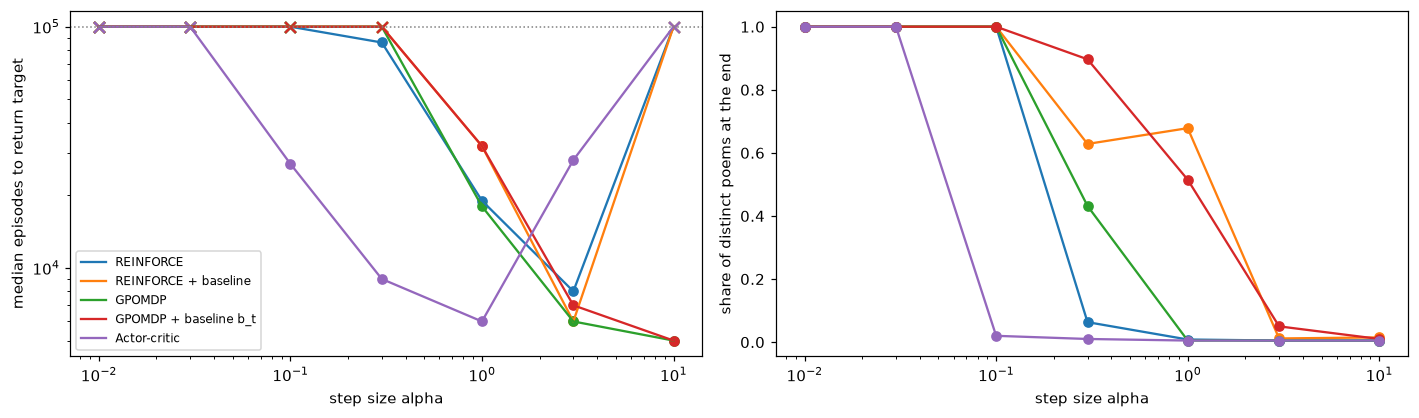

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
print(f'episodes to return >= {TARGET_RETURN} (thousands) per tuning seed, "-" = not reached; final share of distinct poems')
print(f'{"method":24s}' + ''.join(f'{a:>18}' for a in grid))
for m in P.METHODS:
    med, div, cells = [], [], []
    for a in grid:
        rs = [X.run_many([P.spec(m, a, s)], TUNE_CACHE, verbose=False)[0] for s in P.TUNE_SEEDS]
        sc = [P.sample_complexity(r['history'], TARGET_RETURN) for r in rs]
        med.append(np.median([s if s is not None else P.N_EPISODES for s in sc]))
        div.append(np.mean([r['final_metrics']['distinct_poems'] for r in rs]))
        cells.append('/'.join('-' if s is None else f'{s // 1000}' for s in sc) + f'  d={div[-1]:.2f}')
    print(f'{LABELS[m]:24s}' + ''.join(f'{c:>18s}' for c in cells))
    med = np.array(med)
    axes[0].plot(grid, med, '-', color=COLORS[m], label=LABELS[m])
    axes[0].scatter(np.array(grid)[med < P.N_EPISODES], med[med < P.N_EPISODES], color=COLORS[m], marker='o')
    axes[0].scatter(np.array(grid)[med >= P.N_EPISODES], med[med >= P.N_EPISODES], color=COLORS[m], marker='x', s=50)
    axes[1].plot(grid, div, 'o-', color=COLORS[m], label=LABELS[m])
axes[0].axhline(P.N_EPISODES, color='gray', ls=':', lw=1)
axes[0].set_yscale('log'); axes[0].set_ylabel('median episodes to return target')
axes[1].set_ylabel('share of distinct poems at the end')
for ax in axes:
    ax.set_xscale('log'); ax.set_xlabel('step size alpha')
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Final runs

Each method at its tuned $\alpha$, on **10 fresh seeds** (100–109) that were not used for tuning. Curves show the mean and a 95%
$t$-interval over the 10 seeds.

all 50 runs loaded from 04_final.pkl


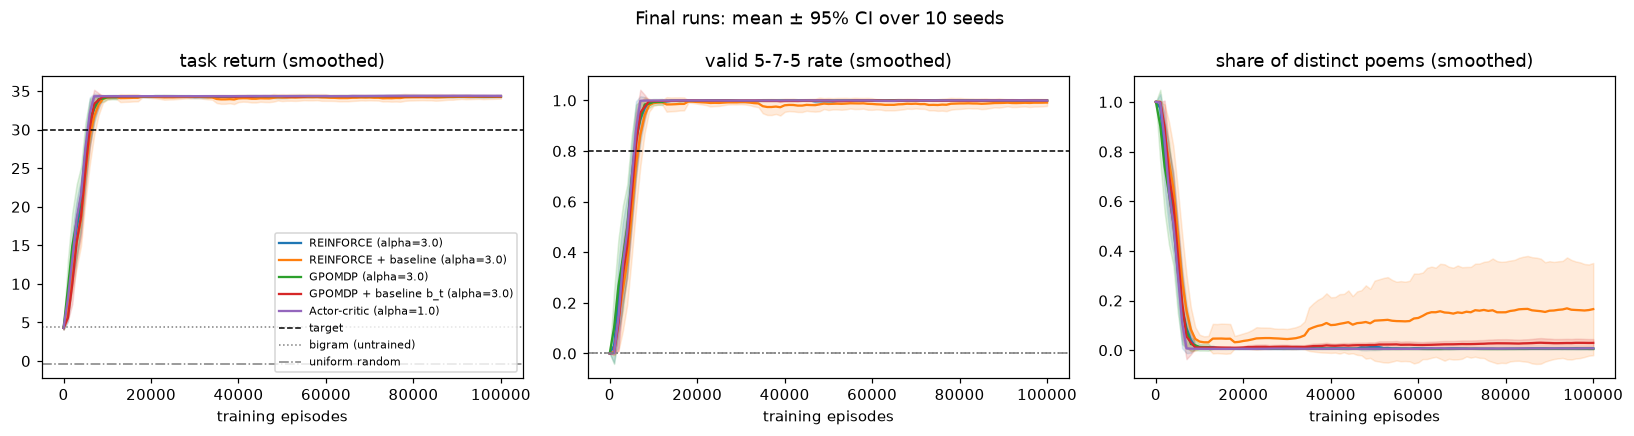

In [8]:
final_specs = {m: [P.spec(m, best[m], s) for s in P.FINAL_SEEDS] for m in P.METHODS}
final = dict(zip(P.METHODS, [None] * len(P.METHODS)))
flat = X.run_many([s for m in P.METHODS for s in final_specs[m]], X.RESULTS_DIR / '04_final.pkl')
for k, m in enumerate(P.METHODS):
    final[m] = flat[k * len(P.FINAL_SEEDS):(k + 1) * len(P.FINAL_SEEDS)]
x = np.array(final['gpomdp_b'][0]['history']['eval_episodes'])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for m in P.METHODS:
    for ax, key in zip(axes, ['return', 'valid', 'distinct_poems']):
        ys = np.array([P.smoothed(r['history'], key) for r in final[m]])
        mean, hw = stats.mean_ci(ys)
        ax.plot(x, mean, color=COLORS[m], label=f'{LABELS[m]} (alpha={best[m]})')
        ax.fill_between(x, mean - hw, mean + hw, color=COLORS[m], alpha=0.15)
for ax, key, t in [(axes[0], 'return', TARGET_RETURN), (axes[1], 'valid', TARGET_VALID)]:
    ax.axhline(t, color='k', ls='--', lw=1, label='target')
    for (name, ref), ls in zip(refs.items(), [':', '-.']):
        ax.axhline(ref[key], color='gray', ls=ls, lw=1, label=name)
axes[0].set_title('task return (smoothed)'); axes[1].set_title('valid 5-7-5 rate (smoothed)'); axes[2].set_title('share of distinct poems (smoothed)')
for ax in axes: ax.set_xlabel('training episodes')
axes[0].legend(fontsize=7, loc='lower right')
fig.suptitle(f'Final runs: mean ± 95% CI over {len(P.FINAL_SEEDS)} seeds')
plt.tight_layout(); plt.show()

In [9]:
def sc_table(key, tgt):
    rows = {}
    for m in P.METHODS:
        sc = [P.sample_complexity(r['history'], tgt, key) for r in final[m]]
        reached = np.array([s for s in sc if s is not None], dtype=float)
        censored = np.array([s if s is not None else P.N_EPISODES for s in sc], dtype=float)
        rows[m] = dict(sc=sc, reached=reached, censored=censored)
    return rows

sc_return = sc_table('return', TARGET_RETURN)
sc_valid = sc_table('valid', TARGET_VALID)

for title, rows in [(f'return >= {TARGET_RETURN}', sc_return), (f'valid rate >= {TARGET_VALID}', sc_valid)]:
    print(f'\nSample complexity (training episodes until the smoothed curve reaches {title}), {len(P.FINAL_SEEDS)} seeds')
    print(f'{"method":24s} {"alpha":>6s} {"reached":>8s} {"mean ± 95% CI (reached runs)":>30s} {"median*":>9s}')
    for m in P.METHODS:
        r = rows[m]
        if len(r['reached']):
            mean, hw = stats.mean_ci(r['reached'])
            ci = f'{mean:9,.0f} ± {hw:7,.0f}'
        else:
            ci = 'never reached'
        print(f'{LABELS[m]:24s} {best[m]:6} {len(r["reached"]):>5d}/{len(r["sc"])} {ci:>30s} {np.median(r["censored"]):9,.0f}')
print('\n* median with "not reached" counted as the budget (a lower bound when some runs did not reach the target)')


Sample complexity (training episodes until the smoothed curve reaches return >= 30.0), 10 seeds
method                    alpha  reached   mean ± 95% CI (reached runs)   median*
REINFORCE                   3.0    10/10                6,500 ±     695     6,000
REINFORCE + baseline        3.0    10/10                7,000 ±     826     7,000
GPOMDP                      3.0    10/10                6,200 ±     657     6,000
GPOMDP + baseline b_t       3.0    10/10                6,700 ±     483     7,000
Actor-critic                1.0    10/10                6,000 ±     477     6,000

Sample complexity (training episodes until the smoothed curve reaches valid rate >= 0.8), 10 seeds
method                    alpha  reached   mean ± 95% CI (reached runs)   median*
REINFORCE                   3.0    10/10                6,500 ±     695     6,000
REINFORCE + baseline        3.0    10/10                7,000 ±     954     7,000
GPOMDP                      3.0    10/10                6,100 ±  

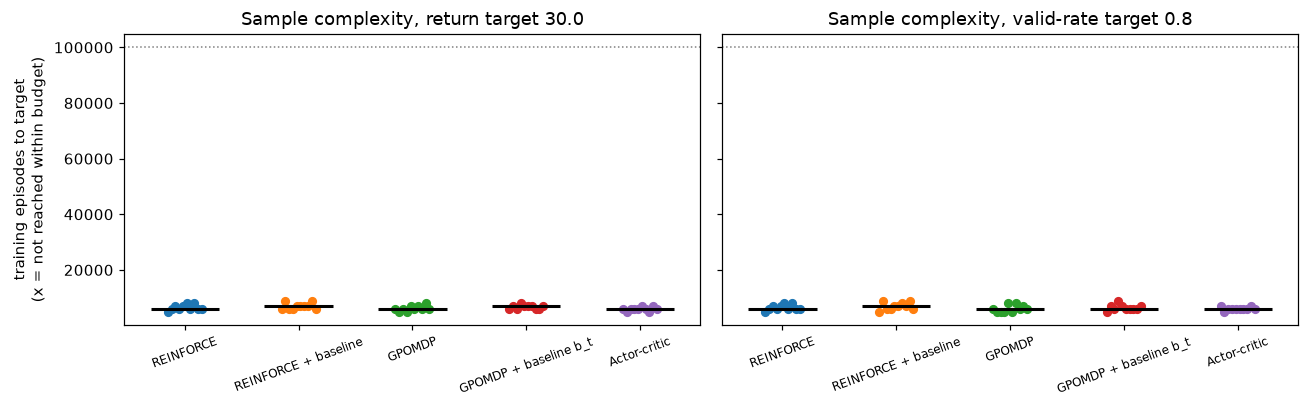

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, rows, title in [(axes[0], sc_return, f'return target {TARGET_RETURN}'), (axes[1], sc_valid, f'valid-rate target {TARGET_VALID}')]:
    for k, m in enumerate(P.METHODS):
        sc = rows[m]['sc']
        jitter = np.linspace(-0.15, 0.15, len(sc))
        ys = [s if s is not None else P.N_EPISODES * 1.04 for s in sc]
        marks = ['o' if s is not None else 'x' for s in sc]
        for j, y, mk in zip(jitter, ys, marks):
            ax.scatter(k + j, y, marker=mk, color=COLORS[m], s=25)
        if len(rows[m]['reached']):
            ax.hlines(np.median(rows[m]['censored']), k - 0.3, k + 0.3, color='k', lw=2)
    ax.axhline(P.N_EPISODES, color='gray', ls=':', lw=1)
    ax.set_xticks(range(len(P.METHODS))); ax.set_xticklabels([LABELS[m] for m in P.METHODS], rotation=20, fontsize=8)
    ax.set_title(f'Sample complexity, {title}')
axes[0].set_ylabel('training episodes to target\n(x = not reached within budget)')
plt.tight_layout(); plt.show()

In [11]:
print(f'Final evaluation (200 fresh poems after the full budget), mean over {len(P.FINAL_SEEDS)} seeds')
cols = ['return', 'valid', 'distinct_poems', 'distinct_words', 'unique_in_poem', 'fluency', 'syl_error']
print(f'{"policy":24s}' + ''.join(f'{c:>15s}' for c in cols))
for name, mtr in refs.items():
    print(f'{name:24s}' + ''.join(f'{mtr[c]:15.3f}' for c in cols))
for m in P.METHODS:
    fm = [r['final_metrics'] for r in final[m]]
    print(f'{LABELS[m]:24s}' + ''.join(f'{np.mean([f[c] for f in fm]):15.3f}' for c in cols))

Final evaluation (200 fresh poems after the full budget), mean over 10 seeds
policy                           return          valid distinct_poems distinct_words unique_in_poem        fluency      syl_error
bigram (untrained)                4.415          0.000          1.000          1.000          0.927         -4.494          2.767
uniform random                   -0.380          0.000          1.000          1.000          0.980         -7.445          3.236
REINFORCE                        34.303          1.000          0.005          0.027          0.900         -3.233          0.000
REINFORCE + baseline             34.279          0.992          0.170          0.107          0.859         -3.283          0.009
GPOMDP                           34.349          1.000          0.005          0.024          0.894         -3.321          0.000
GPOMDP + baseline b_t            34.344          1.000          0.027          0.034          0.867         -3.194          0.001
Actor-critic 

### Poems before and after training

*Before* = the untrained bigram. *After* = the 5 most frequent poems among 200 sampled from the final policy of the first final seed
(seed 100) of each method, with how many times each appeared.

In [12]:
from collections import Counter
pol0 = TabularSoftmax(env.bigram_logits(1.0), 1.0)
print('BEFORE (untrained bigram), 6 samples:')
for tr in ev.sample_poems(env, pol0, 6, np.random.default_rng(3)):
    print('   ', env.format_poem(tr.actions))
for m in P.METHODS:
    r = final[m][0]
    print(f"\nAFTER: {LABELS[m]} (alpha = {best[m]}, seed {r['spec']['seed']}): "
          f"{len(r['final_poems'])} distinct poems out of 200, valid {r['final_metrics']['valid']:.0%}")
    for poem, n in r['final_poems'][:5]:
        print(f'   {n:4d}x  {poem}')

BEFORE (untrained bigram), 6 samples:
    the ground (2) / when the greeks have i am in a bow or (10) / when we look at every lost (8)
    i the helmet for i also (8) / when you gave the main land and every (10) / minerva had left in vain (7)
    with bright rise flew (4) / but go country and dreadful day till the (10) / what they sat their lord as it for (8)
    to hear flies stay (4) / in time in word gave yet rich seat under (10) / the hero his eyes in himself (8)
    and you will find (4) / there you if thou the rest no till ulysses (11) / thus she down to one of her life (8)
    these no then be a body at (8) / you either earth at that not to man (9) / so much wood (3)

AFTER: REINFORCE (alpha = 3.0, seed 100): 1 distinct poems out of 200, valid 100%
    200x  let us in the field (5) / and all their work of the plain (7) / now come back to end (5)

AFTER: REINFORCE + baseline (alpha = 3.0, seed 100): 4 distinct poems out of 200, valid 100%
     88x  on a mortal fight (5) / but uly

## 6. Discussion

**Main result: two regimes.**
- **With the shaped reward (this notebook), all methods tie at their tuned step size.** Every method reaches the target in about the
  same number of episodes (6 000–7 000, overlapping confidence intervals).
- **With line-only rewards (notebook 05), variance reduction decides whether a run succeeds at all.** That reward pays only +1 per exact
  line and +1 for a valid poem. Under it:
  - REINFORCE reaches the valid-rate target in 4/10 runs, after 30 750 episodes on average over those 4;
  - GPOMDP + $b_t$ reaches it in 9/10 runs, after 4 900 ± 260 episodes, about 6× fewer;
  - REINFORCE + $b$ reaches it in 10/10 (9 100) and GPOMDP in 7/10 (13 100);
  - every run that misses is locked into a near-miss poem.

  With the dense shaped reward, every update carries enough signal (and the KL term keeps enough exploration) that the noise of the
  estimator does not matter at a well-chosen step size. With the sparser line rewards it does.

**The shaped regime in detail.** All 50 final runs reach both targets. The mean sample complexity ranges from about 6 000 (actor-critic, GPOMDP) to 7 000 episodes
(REINFORCE + baseline), and the 95% intervals overlap. The measurement itself has a resolution of about 1 000–2 000 episodes:
one evaluation every 1 000 episodes, and a trailing 5 000-episode smoothing window that delays every crossing by the same amount for
all methods. So, **at the best step size, we see no sample-complexity advantage of variance reduction in this problem.** We report
this as it is, instead of changing the target or the protocol after seeing the result.

**Why the methods tie: the target can be reached by memorising one poem.** At the tuned step sizes ($\alpha = 3$ for the batch
methods, $\alpha=1$ for the actor-critic), every method collapses within ~6 000 episodes onto one to four valid poems (final share of
distinct poems 0.5–17%). With a tabular softmax, a large step on a handful of sampled poems is essentially "copy the best poem in the
batch", and that is all a return target asks for. Variance reduction makes each gradient *more accurate*, but here an accurate gradient
is not needed to reach the target: any valid poem will do.

**Where the methods do differ: the whole step-size range (§4).**
- **Without a baseline, the methods are *faster* at moderate step sizes, but they collapse.** At $\alpha = 1$, REINFORCE and GPOMDP reach
  the target after 15–28k episodes and end with ~1% distinct poems. REINFORCE + $b$ and GPOMDP + $b_t$ need 15–46k but keep 52–68% distinct
  poems. Our returns are mostly positive (the progress term alone gives up to 17), so without a baseline the "noise" term
  $\nabla\log\pi(A\mid S)\cdot R$ pushes up *every sampled action*. That is a rich-get-richer drift that lowers entropy and commits the policy
  to whatever it samples often. Unbiasedness only says this drift is zero *on average*. For a single run it is a systematic push toward a
  deterministic policy, which happens to help with a "reach any valid poem" target. Baselines remove most of it (notebook 06 measures
  how much variance they remove), so the baselined methods follow the true gradient more closely, and stay stochastic longer.
- **GPOMDP's variance reduction shows up as robustness to large steps.** At $\alpha = 10$ both REINFORCE variants mostly fail (the policy jumps
  onto a bad deterministic poem and the softmax gradient vanishes, the "wrong arm" failure of notebook 02). GPOMDP and GPOMDP + $b_t$ still
  reach the target in ~5 000 episodes. Dropping the rewards that precede each action removes noise that, at such step sizes, is the
  difference between converging and getting stuck.
- **The actor-critic is the most sample-efficient at small step sizes.** It is the only method that reaches the target at $\alpha = 0.1$
  (26–28k episodes), and it is the fastest at $\alpha = 1$. Part of this is the step-size scale: it updates after every *step* (about 20 updates
  per episode), while a batch method makes one update per 10 episodes. The other part is the critic: $\delta_t$ uses the learned $V_w$ as a
  state-dependent baseline. It becomes unstable for $\alpha \ge 3$. Note that at its tuned $\alpha = 1$ the critic step is
  $\beta = \min(10\alpha, 1) = 1$, so the usual recommendation $\alpha \ll \beta$ holds only for $\alpha \le 0.1$. With $\beta = 1$ the tabular
  critic simply stores the last TD target of each state.

**Memorisation is what the objective asks for.** Maximising expected return admits an optimal policy that is *deterministic* and
Markov: an MDP always has a deterministic optimal policy (this is usually proved for the discounted criterion, and the same
argument applies to our finite-horizon episodes), so randomising never increases the value. A policy that always writes the single
best-scoring poem is therefore optimal. The tabular softmax can approach it as closely as it likes, and gradient ascent drifts towards it.
Collapse onto one or a few poems is the expected outcome, not a bug.

The KL penalty changes the objective to $\mathbb E[\sum_t r_t - \eta(\log\pi_\theta(A_t|S_t) - \log P_{\text{bigram}}(A_t|S_t))]$. Its optimum
is stochastic:
$$\pi^*_\eta(a\mid s) \propto P_{\text{bigram}}(a\mid s)\,\exp\!\big(Q^*_\eta(s,a)/\eta\big),$$
where $Q^*_\eta$ is the KL-regularised ("soft") action value. An action whose value is $\Delta$ below the best keeps a relative weight of
about $e^{-\Delta/\eta}$ (times its bigram ratio). So the optimum stays diverse only where the value gaps are comparable to $\eta$. Here a
word that costs one exact line loses about 3 (the line bonus), plus the completion bonus 10 if it breaks a valid poem. With η = 0.5 that is
a factor of $e^{-6} \approx 0.25\%$ or less, so the regularised optimum is nearly deterministic wherever the next word decides validity,
and stochastic only among words of almost equal value. Notebook 03's sweep shows the trade-off from the other side:
- η ≤ 0.3 collapses onto a single poem;
- η = 0.5 still had 43% distinct poems after 50k episodes at α = 1;
- η = 1 keeps every poem distinct, but only 6% are valid, because η is then of the same order as the bonuses themselves.

**Diversity.** Even with the KL penalty (η = 0.5), all tuned methods end up memorising: η = 0.5 was chosen in notebook 03 at
$\alpha = 1$, where it kept ~40% of poems distinct, but at the tuned $\alpha = 3$ the large steps overwhelm it. The return and valid-rate
targets do not reward diversity, so the tuning picks the step sizes that collapse fastest. A target that also required, say, 30% distinct
poems would reward the baselined methods at $\alpha \approx 1$. We did not use one, because the targets were fixed before the comparison.

**Limitations.** Only 3 seeds per grid value for tuning (10 for the final runs). One budget, one batch size ($n = 10$) and one temperature
($\tau=1$). The sample-complexity resolution is limited by the evaluation interval. The variance ranking behind these results is measured
directly in notebook 06, and the role of the dense reward in notebook 05.